# Data Mining — Lab 3: Decision Tree Analysis

**Datasets:** German Credit (binary, 1000 samples) · Waveform v1 (3-class, 5000 samples)

| Part | Description |
|------|-------------|
| I    | Decision Tree with **Gini** — Holdout (5 × 90/10) + 10-Fold CV |
| II   | Decision Tree with **Entropy** — same protocol, compare with Part I |
| III  | Effect of **tree depth** on accuracy (holdout, depth 2–50) |

## Imports & Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import subprocess
import io
import os
import json

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import accuracy_score, precision_score, f1_score

%matplotlib inline
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10})

BASE = "/Users/abdullah/Documents/Data_Mining/Labs/Lab 3"
OUT  = f"{BASE}/output"
os.makedirs(OUT, exist_ok=True)
print("Output directory:", OUT)

Output directory: /Users/abdullah/Documents/Data_Mining/Labs/Lab 3/output


## Load Datasets

In [2]:
# --- German Credit (space-separated numeric, last col: 1=good, 2=bad → remapped 0/1) ---
german_raw = pd.read_csv(
    f"{BASE}/statlog+german+credit+data/german.data-numeric",
    sep=r'\s+', header=None)
X_german = german_raw.iloc[:, :-1].values.astype(float)
y_german  = (german_raw.iloc[:, -1].values - 1)   # 1,2 → 0,1

# --- Waveform (comma-separated, last col: 0/1/2, stored as .Z compressed) ---
proc = subprocess.run(
    ['uncompress', '-c',
     f"{BASE}/waveform+database+generator+version+1/waveform.data.Z"],
    capture_output=True, check=True)
waveform_df = pd.read_csv(io.BytesIO(proc.stdout), header=None)
X_wave = waveform_df.iloc[:, :-1].values.astype(float)
y_wave = waveform_df.iloc[:, -1].values

print(f"German Credit : X={X_german.shape}, classes={np.unique(y_german)}, "
      f"class counts={dict(zip(*np.unique(y_german, return_counts=True)))}")
print(f"Waveform      : X={X_wave.shape},  classes={np.unique(y_wave)}, "
      f"class counts={dict(zip(*np.unique(y_wave, return_counts=True)))}")

DATASETS = [
    ('German Credit', 'german', X_german, y_german),
    ('Waveform',      'wave',   X_wave,   y_wave),
]

German Credit : X=(1000, 24), classes=[0 1], class counts={np.int64(0): np.int64(700), np.int64(1): np.int64(300)}
Waveform      : X=(5000, 21),  classes=[0 1 2], class counts={np.int64(0): np.int64(1657), np.int64(1): np.int64(1647), np.int64(2): np.int64(1696)}


## Helper Functions

In [3]:
def metrics(y_true, y_pred):
    """Weighted Accuracy, Precision, F-measure."""
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    f1   = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    return acc, prec, f1


def holdout_experiment(X, y, criterion, n_trials=5, test_size=0.1, seed=0):
    """Run n_trials independent 90/10 holdout splits and return a results DataFrame."""
    rows = []
    for i in range(n_trials):
        X_tr, X_te, y_tr, y_te = train_test_split(
            X, y, test_size=test_size, random_state=seed + i)
        clf = DecisionTreeClassifier(criterion=criterion, random_state=seed + i)
        clf.fit(X_tr, y_tr)
        acc, prec, f1 = metrics(y_te, clf.predict(X_te))
        rows.append({'Label': f'Trial {i+1}', 'Accuracy': acc,
                     'Precision': prec, 'F-measure': f1})
    df = pd.DataFrame(rows)
    avg = df[['Accuracy', 'Precision', 'F-measure']].mean()
    df = pd.concat([df, pd.DataFrame([{'Label': 'Average', **avg.to_dict()}])],
                   ignore_index=True)
    return df


def cv_experiment(X, y, criterion, n_folds=10, seed=0):
    """Run n_folds-fold cross-validation and return a results DataFrame."""
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=seed)
    rows = []
    for i, (tr_idx, te_idx) in enumerate(kf.split(X)):
        clf = DecisionTreeClassifier(criterion=criterion, random_state=seed)
        clf.fit(X[tr_idx], y[tr_idx])
        acc, prec, f1 = metrics(y[te_idx], clf.predict(X[te_idx]))
        rows.append({'Label': f'Fold {i+1}', 'Accuracy': acc,
                     'Precision': prec, 'F-measure': f1})
    df = pd.DataFrame(rows)
    avg = df[['Accuracy', 'Precision', 'F-measure']].mean()
    df = pd.concat([df, pd.DataFrame([{'Label': 'Average', **avg.to_dict()}])],
                   ignore_index=True)
    return df


def bar_chart(df, title, filepath):
    """Grouped bar chart: Accuracy / Precision / F-measure per trial or fold."""
    labels = df['Label'].tolist()
    n = len(labels)
    x = np.arange(n)
    w = 0.26

    fig, ax = plt.subplots(figsize=(max(9, n * 0.75), 4.5))
    b1 = ax.bar(x - w, df['Accuracy'],  w, label='Accuracy',  color='#2B7BB9')
    b2 = ax.bar(x,     df['Precision'], w, label='Precision', color='#E87722')
    b3 = ax.bar(x + w, df['F-measure'], w, label='F-measure', color='#3BAA34')

    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=40, ha='right', fontsize=9)
    ax.set_ylim(0, 1.12)
    ax.set_ylabel('Score')
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.legend(fontsize=9)
    ax.axvline(n - 1.5, color='gray', linestyle='--', lw=0.8, alpha=0.7)

    # Annotate the average bars
    for b in [b1, b2, b3]:
        bar = list(b)[-1]
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.015,
                f'{bar.get_height():.3f}',
                ha='center', va='bottom', fontsize=7, fontweight='bold')

    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig(filepath, dpi=150, bbox_inches='tight')
    plt.show()


def depth_experiment(X, y, criterion, depths, seed=0):
    """Measure train/test accuracy for each depth using a single 90/10 holdout."""
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.1, random_state=seed)
    train_acc, test_acc = [], []
    for d in depths:
        clf = DecisionTreeClassifier(criterion=criterion,
                                     max_depth=d, random_state=seed)
        clf.fit(X_tr, y_tr)
        train_acc.append(accuracy_score(y_tr, clf.predict(X_tr)))
        test_acc.append(accuracy_score(y_te, clf.predict(X_te)))
    return train_acc, test_acc


def depth_plot(depths, train_acc, test_acc, title, filepath):
    """Line chart of training vs test accuracy across tree depths."""
    best_d = depths[int(np.argmax(test_acc))]

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(depths, train_acc, 'o-',  color='#2B7BB9', label='Train Accuracy', lw=1.8)
    ax.plot(depths, test_acc,  's--', color='#E87722', label='Test Accuracy',  lw=1.8)
    ax.axvline(best_d, color='green', linestyle=':', lw=1.4, alpha=0.8,
               label=f'Best test depth = {best_d}')
    ax.set_xlabel('Max Tree Depth')
    ax.set_ylabel('Accuracy')
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.legend(fontsize=9)
    ax.set_xticks(depths)
    ax.tick_params(axis='x', rotation=45)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(filepath, dpi=150, bbox_inches='tight')
    plt.show()


print("All helper functions defined.")

All helper functions defined.


---
# Part I — Decision Tree with Gini Impurity

For each dataset:
- **Holdout**: 90% train / 10% test, repeated **5 times** with different random seeds
- **10-Fold Cross-Validation**: standard KFold with shuffle

Metrics reported: **Accuracy**, **Precision** (weighted), **F-measure** (weighted)

## 1.1 German Credit — Holdout (Gini)

,Label,Accuracy,Precision,F-measure
0,Trial 1,0.6600,0.7044,0.6762
1,Trial 2,0.6700,0.6669,0.6684
2,Trial 3,0.6600,0.6491,0.6535
3,Trial 4,0.6500,0.6471,0.6485
4,Trial 5,0.6300,0.6499,0.6385
5,Average,0.6540,0.6635,0.6570


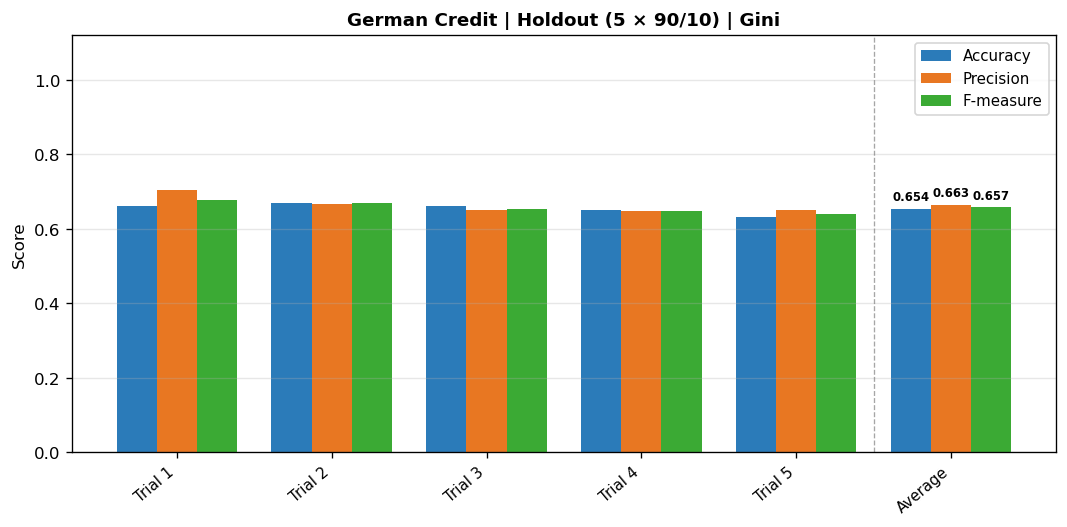

In [4]:
ho_german_gini = holdout_experiment(X_german, y_german, criterion='gini')

display(ho_german_gini.style
        .format({'Accuracy': '{:.4f}', 'Precision': '{:.4f}', 'F-measure': '{:.4f}'})
        .set_caption('German Credit — Holdout Results (Gini)')
        .highlight_max(subset=['Accuracy','Precision','F-measure'],
                       props='font-weight:bold; color:steelblue')
        .set_properties(**{'text-align': 'center'}))

bar_chart(
    ho_german_gini,
    'German Credit | Holdout (5 × 90/10) | Gini',
    f'{OUT}/german_holdout_gini.png')

## 1.2 German Credit — 10-Fold Cross-Validation (Gini)

,Label,Accuracy,Precision,F-measure
0,Fold 1,0.6600,0.7044,0.6762
1,Fold 2,0.6300,0.6329,0.6314
2,Fold 3,0.7000,0.6936,0.6965
3,Fold 4,0.7300,0.7454,0.7342
4,Fold 5,0.7200,0.7141,0.7167
5,Fold 6,0.5900,0.6300,0.6058
6,Fold 7,0.7300,0.7215,0.7238
7,Fold 8,0.6700,0.6894,0.6781
8,Fold 9,0.6500,0.6832,0.6617
9,Fold 10,0.7200,0.7163,0.7178


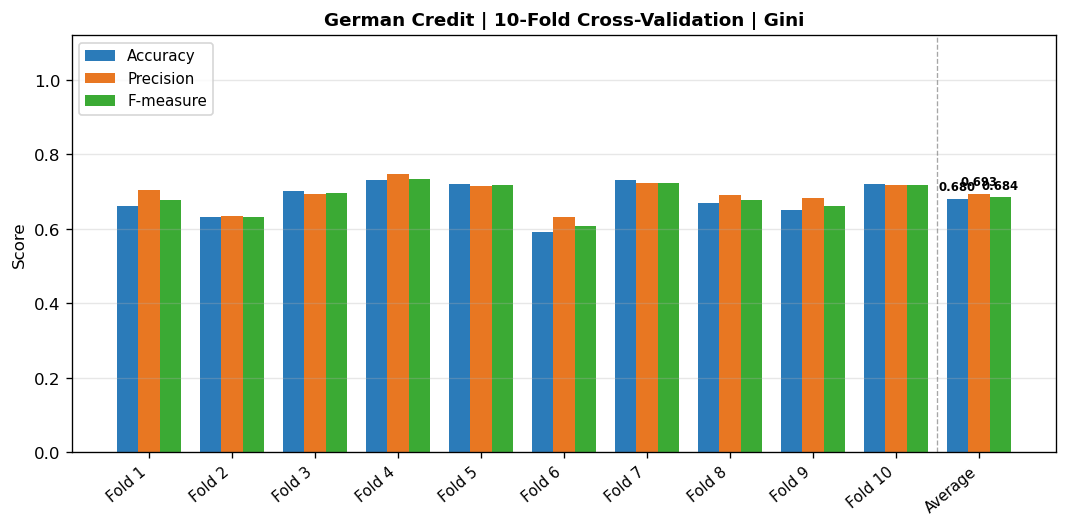

In [5]:
cv_german_gini = cv_experiment(X_german, y_german, criterion='gini')

display(cv_german_gini.style
        .format({'Accuracy': '{:.4f}', 'Precision': '{:.4f}', 'F-measure': '{:.4f}'})
        .set_caption('German Credit — 10-Fold CV Results (Gini)')
        .highlight_max(subset=['Accuracy','Precision','F-measure'],
                       props='font-weight:bold; color:steelblue')
        .set_properties(**{'text-align': 'center'}))

bar_chart(
    cv_german_gini,
    'German Credit | 10-Fold Cross-Validation | Gini',
    f'{OUT}/german_cv_gini.png')

## 1.3 Waveform — Holdout (Gini)

,Label,Accuracy,Precision,F-measure
0,Trial 1,0.7440,0.7467,0.7438
1,Trial 2,0.7160,0.7180,0.7162
2,Trial 3,0.7760,0.7781,0.7763
3,Trial 4,0.7400,0.7405,0.7394
4,Trial 5,0.7680,0.7680,0.7679
5,Average,0.7488,0.7503,0.7487


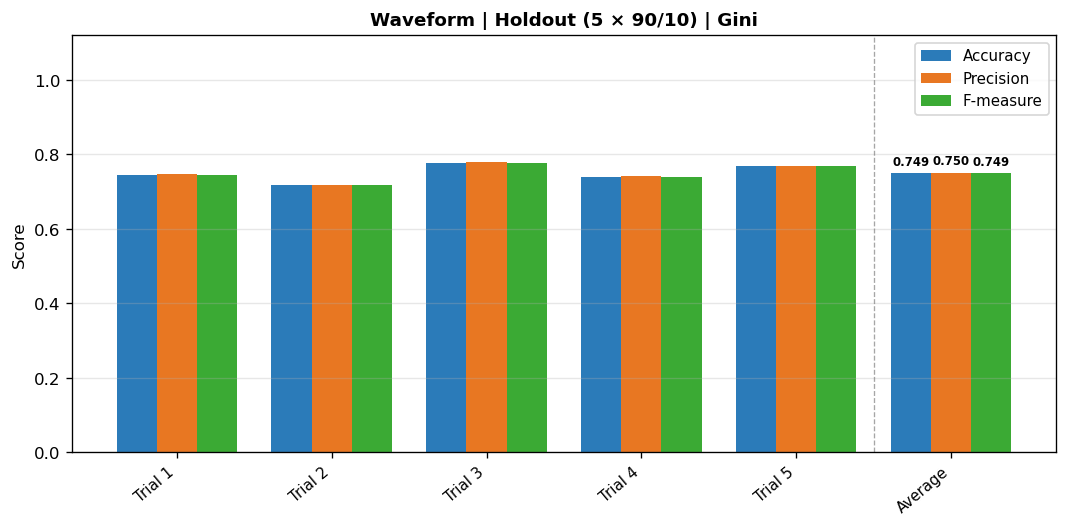

In [6]:
ho_wave_gini = holdout_experiment(X_wave, y_wave, criterion='gini')

display(ho_wave_gini.style
        .format({'Accuracy': '{:.4f}', 'Precision': '{:.4f}', 'F-measure': '{:.4f}'})
        .set_caption('Waveform — Holdout Results (Gini)')
        .highlight_max(subset=['Accuracy','Precision','F-measure'],
                       props='font-weight:bold; color:steelblue')
        .set_properties(**{'text-align': 'center'}))

bar_chart(
    ho_wave_gini,
    'Waveform | Holdout (5 × 90/10) | Gini',
    f'{OUT}/wave_holdout_gini.png')

## 1.4 Waveform — 10-Fold Cross-Validation (Gini)

,Label,Accuracy,Precision,F-measure
0,Fold 1,0.7440,0.7467,0.7438
1,Fold 2,0.7440,0.7444,0.7437
2,Fold 3,0.7680,0.7698,0.7682
3,Fold 4,0.7440,0.7448,0.7441
4,Fold 5,0.7340,0.7362,0.7344
5,Fold 6,0.7560,0.7555,0.7552
6,Fold 7,0.7720,0.7729,0.7713
7,Fold 8,0.7700,0.7704,0.7700
8,Fold 9,0.7180,0.7189,0.7179
9,Fold 10,0.7080,0.7101,0.7085


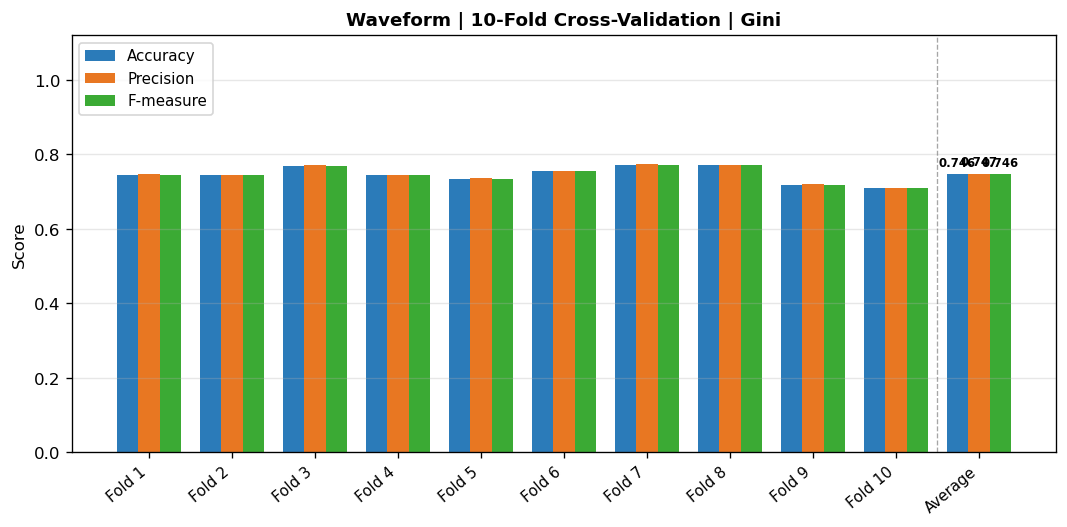

In [7]:
cv_wave_gini = cv_experiment(X_wave, y_wave, criterion='gini')

display(cv_wave_gini.style
        .format({'Accuracy': '{:.4f}', 'Precision': '{:.4f}', 'F-measure': '{:.4f}'})
        .set_caption('Waveform — 10-Fold CV Results (Gini)')
        .highlight_max(subset=['Accuracy','Precision','F-measure'],
                       props='font-weight:bold; color:steelblue')
        .set_properties(**{'text-align': 'center'}))

bar_chart(
    cv_wave_gini,
    'Waveform | 10-Fold Cross-Validation | Gini',
    f'{OUT}/wave_cv_gini.png')

---
# Part II — Decision Tree with Entropy Impurity

Same holdout and CV protocol as Part I, but using `criterion='entropy'` (Information Gain).  
Results are compared to Part I at the end of this section.

## 2.1 German Credit — Holdout (Entropy)

,Label,Accuracy,Precision,F-measure
0,Trial 1,0.7000,0.7329,0.7122
1,Trial 2,0.6400,0.6609,0.6483
2,Trial 3,0.6500,0.6716,0.6578
3,Trial 4,0.6800,0.6749,0.6772
4,Trial 5,0.6600,0.6600,0.6600
5,Average,0.6660,0.6801,0.6711


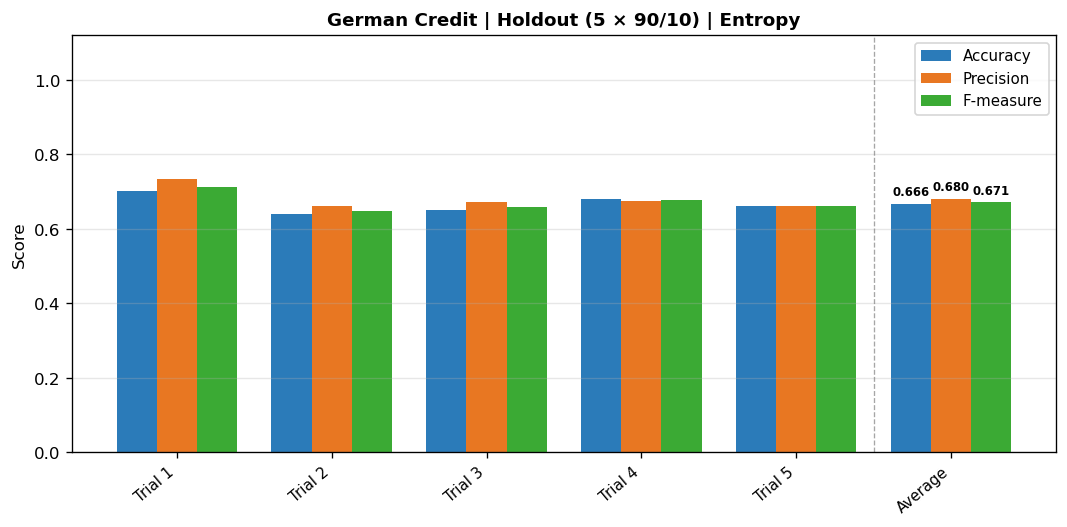

In [8]:
ho_german_ent = holdout_experiment(X_german, y_german, criterion='entropy')

display(ho_german_ent.style
        .format({'Accuracy': '{:.4f}', 'Precision': '{:.4f}', 'F-measure': '{:.4f}'})
        .set_caption('German Credit — Holdout Results (Entropy)')
        .highlight_max(subset=['Accuracy','Precision','F-measure'],
                       props='font-weight:bold; color:darkorange')
        .set_properties(**{'text-align': 'center'}))

bar_chart(
    ho_german_ent,
    'German Credit | Holdout (5 × 90/10) | Entropy',
    f'{OUT}/german_holdout_entropy.png')

## 2.2 German Credit — 10-Fold Cross-Validation (Entropy)

,Label,Accuracy,Precision,F-measure
0,Fold 1,0.7000,0.7329,0.7122
1,Fold 2,0.6400,0.6400,0.6400
2,Fold 3,0.7700,0.7632,0.7658
3,Fold 4,0.7500,0.7486,0.7492
4,Fold 5,0.7500,0.7342,0.7379
5,Fold 6,0.6200,0.6626,0.6357
6,Fold 7,0.6900,0.6877,0.6888
7,Fold 8,0.6200,0.6626,0.6357
8,Fold 9,0.6900,0.6869,0.6884
9,Fold 10,0.7000,0.6924,0.6950


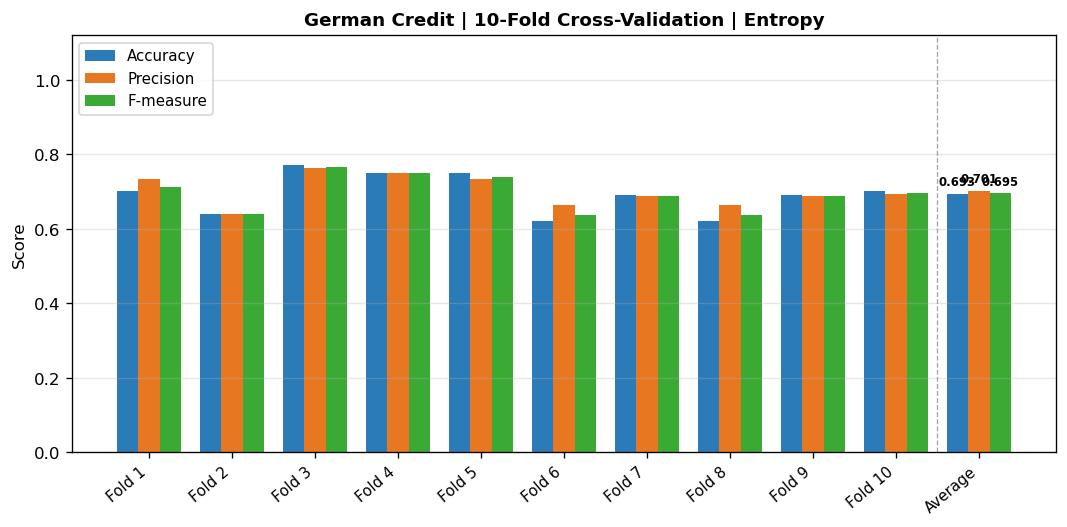

In [9]:
cv_german_ent = cv_experiment(X_german, y_german, criterion='entropy')

display(cv_german_ent.style
        .format({'Accuracy': '{:.4f}', 'Precision': '{:.4f}', 'F-measure': '{:.4f}'})
        .set_caption('German Credit — 10-Fold CV Results (Entropy)')
        .highlight_max(subset=['Accuracy','Precision','F-measure'],
                       props='font-weight:bold; color:darkorange')
        .set_properties(**{'text-align': 'center'}))

bar_chart(
    cv_german_ent,
    'German Credit | 10-Fold Cross-Validation | Entropy',
    f'{OUT}/german_cv_entropy.png')

## 2.3 Waveform — Holdout (Entropy)

,Label,Accuracy,Precision,F-measure
0,Trial 1,0.7360,0.7392,0.7359
1,Trial 2,0.7440,0.7468,0.7445
2,Trial 3,0.7320,0.7363,0.7330
3,Trial 4,0.7920,0.7919,0.7919
4,Trial 5,0.7400,0.7409,0.7401
5,Average,0.7488,0.7510,0.7491


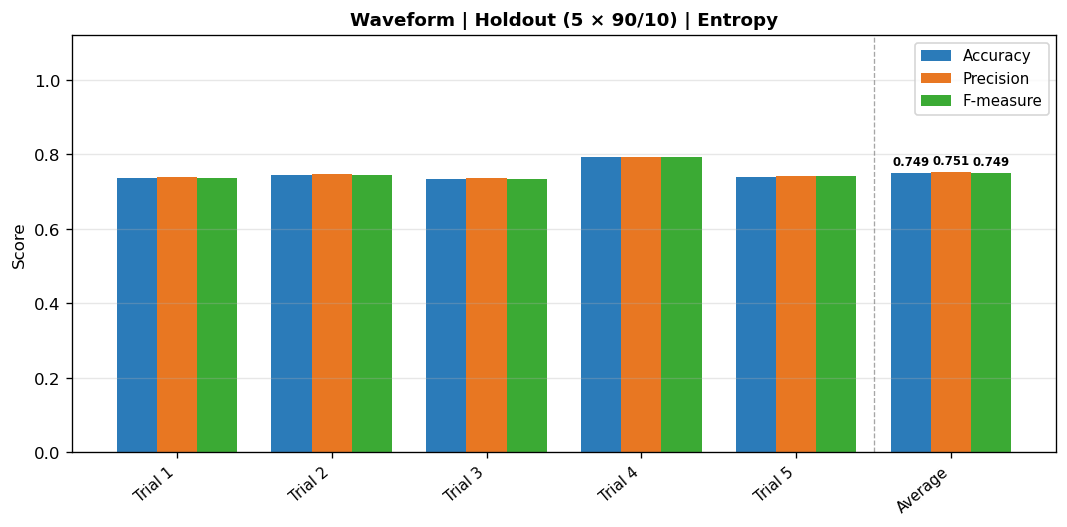

In [10]:
ho_wave_ent = holdout_experiment(X_wave, y_wave, criterion='entropy')

display(ho_wave_ent.style
        .format({'Accuracy': '{:.4f}', 'Precision': '{:.4f}', 'F-measure': '{:.4f}'})
        .set_caption('Waveform — Holdout Results (Entropy)')
        .highlight_max(subset=['Accuracy','Precision','F-measure'],
                       props='font-weight:bold; color:darkorange')
        .set_properties(**{'text-align': 'center'}))

bar_chart(
    ho_wave_ent,
    'Waveform | Holdout (5 × 90/10) | Entropy',
    f'{OUT}/wave_holdout_entropy.png')

## 2.4 Waveform — 10-Fold Cross-Validation (Entropy)

,Label,Accuracy,Precision,F-measure
0,Fold 1,0.7360,0.7392,0.7359
1,Fold 2,0.7780,0.7778,0.7775
2,Fold 3,0.7460,0.7488,0.7469
3,Fold 4,0.7520,0.7513,0.7514
4,Fold 5,0.7680,0.7681,0.7680
5,Fold 6,0.7640,0.7640,0.7636
6,Fold 7,0.7540,0.7537,0.7537
7,Fold 8,0.7520,0.7520,0.7520
8,Fold 9,0.7720,0.7717,0.7717
9,Fold 10,0.7580,0.7591,0.7578


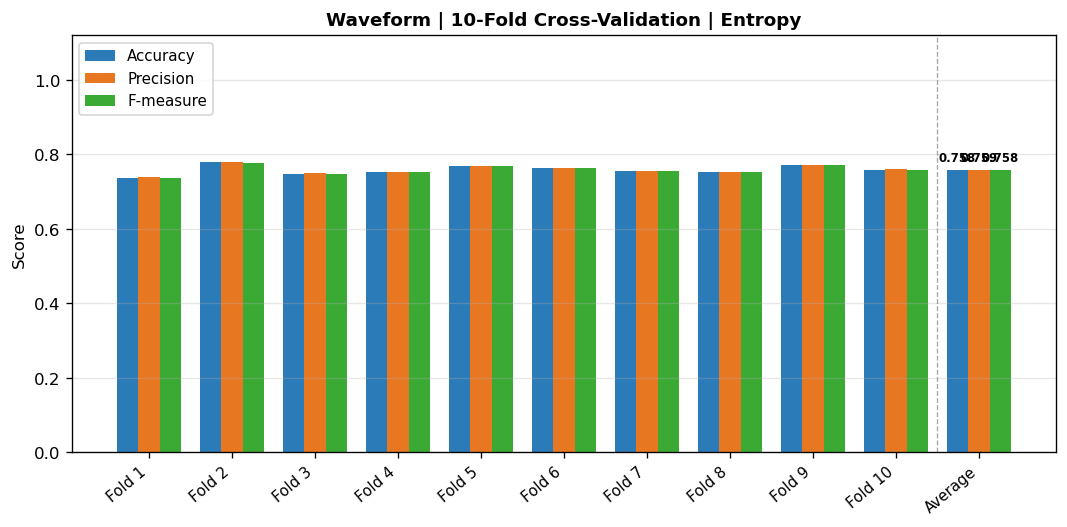

In [11]:
cv_wave_ent = cv_experiment(X_wave, y_wave, criterion='entropy')

display(cv_wave_ent.style
        .format({'Accuracy': '{:.4f}', 'Precision': '{:.4f}', 'F-measure': '{:.4f}'})
        .set_caption('Waveform — 10-Fold CV Results (Entropy)')
        .highlight_max(subset=['Accuracy','Precision','F-measure'],
                       props='font-weight:bold; color:darkorange')
        .set_properties(**{'text-align': 'center'}))

bar_chart(
    cv_wave_ent,
    'Waveform | 10-Fold Cross-Validation | Entropy',
    f'{OUT}/wave_cv_entropy.png')

## 2.5 Comparison: Gini vs. Entropy — CV Accuracy

Side-by-side: fold-by-fold accuracy line plot **and** average accuracy bar chart.

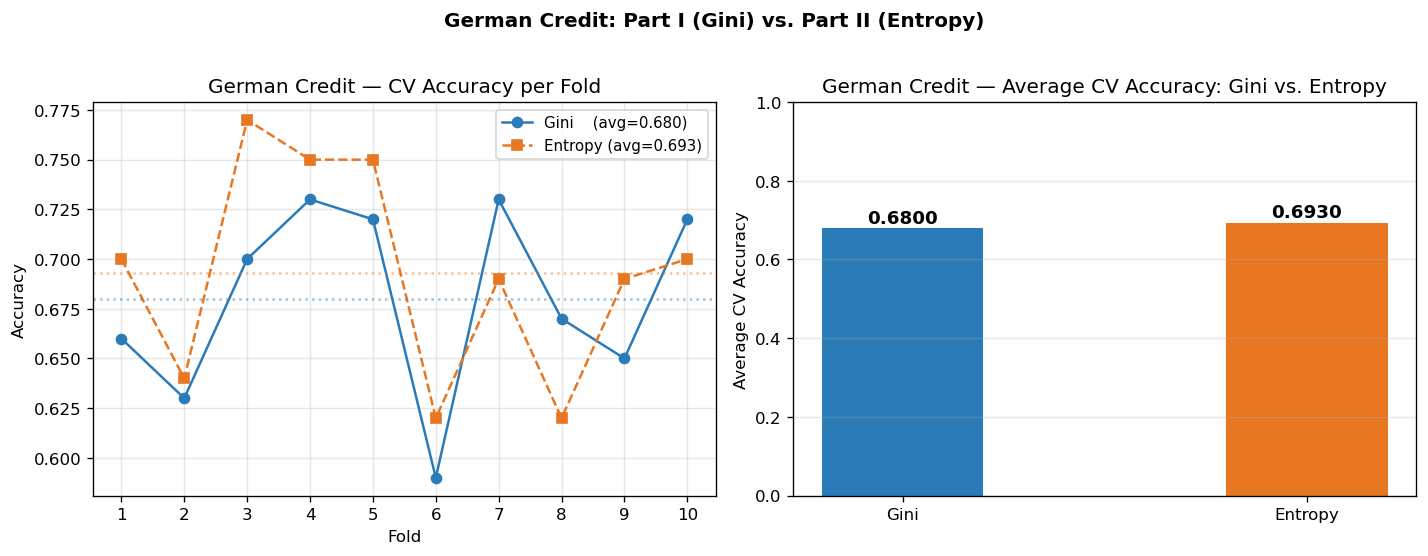


Gini avg CV accuracy   : 0.6800
Entropy avg CV accuracy: 0.6930
Entropy improvement    : +0.0130


In [12]:
# ── German Credit ──────────────────────────────────────────────────────────────
g_vals = cv_german_gini[cv_german_gini['Label'] != 'Average']['Accuracy'].values
e_vals = cv_german_ent [cv_german_ent ['Label'] != 'Average']['Accuracy'].values
folds  = np.arange(1, 11)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ax = axes[0]
ax.plot(folds, g_vals, 'o-',  color='#2B7BB9', label=f'Gini    (avg={g_vals.mean():.3f})')
ax.plot(folds, e_vals, 's--', color='#E87722', label=f'Entropy (avg={e_vals.mean():.3f})')
ax.axhline(g_vals.mean(), color='#2B7BB9', linestyle=':', alpha=0.45)
ax.axhline(e_vals.mean(), color='#E87722', linestyle=':', alpha=0.45)
ax.set_xlabel('Fold'); ax.set_ylabel('Accuracy')
ax.set_title('German Credit — CV Accuracy per Fold')
ax.set_xticks(folds); ax.legend(fontsize=9); ax.grid(alpha=0.3)

ax2 = axes[1]
bars = ax2.bar(['Gini', 'Entropy'], [g_vals.mean(), e_vals.mean()],
               color=['#2B7BB9', '#E87722'], width=0.4)
for b in bars:
    ax2.text(b.get_x() + b.get_width()/2, b.get_height() + 0.003,
             f'{b.get_height():.4f}', ha='center', va='bottom',
             fontsize=11, fontweight='bold')
ax2.set_ylabel('Average CV Accuracy'); ax2.set_ylim(0, 1)
ax2.set_title('German Credit — Average CV Accuracy: Gini vs. Entropy')
ax2.grid(axis='y', alpha=0.3)

plt.suptitle('German Credit: Part I (Gini) vs. Part II (Entropy)',
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'{OUT}/german_compare_cv.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nGini avg CV accuracy   : {g_vals.mean():.4f}")
print(f"Entropy avg CV accuracy: {e_vals.mean():.4f}")
print(f"Entropy improvement    : +{(e_vals.mean()-g_vals.mean()):.4f}")

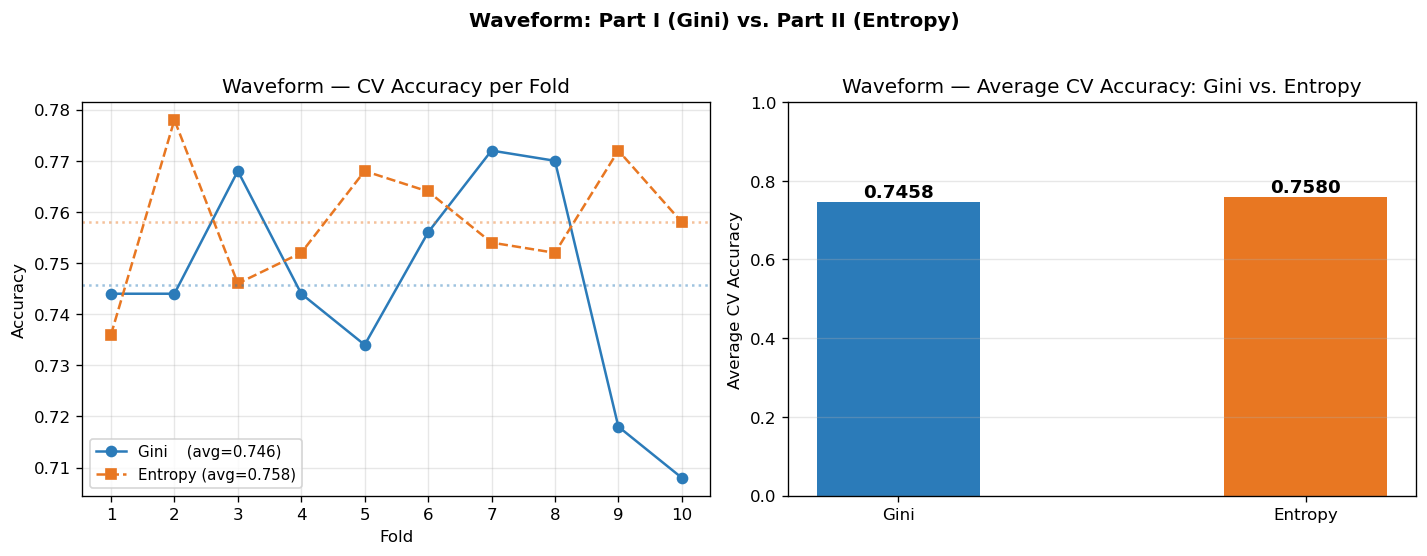


Gini avg CV accuracy   : 0.7458
Entropy avg CV accuracy: 0.7580
Entropy improvement    : +0.0122


In [13]:
# ── Waveform ───────────────────────────────────────────────────────────────────
g_vals_w = cv_wave_gini[cv_wave_gini['Label'] != 'Average']['Accuracy'].values
e_vals_w = cv_wave_ent [cv_wave_ent ['Label'] != 'Average']['Accuracy'].values

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ax = axes[0]
ax.plot(folds, g_vals_w, 'o-',  color='#2B7BB9', label=f'Gini    (avg={g_vals_w.mean():.3f})')
ax.plot(folds, e_vals_w, 's--', color='#E87722', label=f'Entropy (avg={e_vals_w.mean():.3f})')
ax.axhline(g_vals_w.mean(), color='#2B7BB9', linestyle=':', alpha=0.45)
ax.axhline(e_vals_w.mean(), color='#E87722', linestyle=':', alpha=0.45)
ax.set_xlabel('Fold'); ax.set_ylabel('Accuracy')
ax.set_title('Waveform — CV Accuracy per Fold')
ax.set_xticks(folds); ax.legend(fontsize=9); ax.grid(alpha=0.3)

ax2 = axes[1]
bars = ax2.bar(['Gini', 'Entropy'], [g_vals_w.mean(), e_vals_w.mean()],
               color=['#2B7BB9', '#E87722'], width=0.4)
for b in bars:
    ax2.text(b.get_x() + b.get_width()/2, b.get_height() + 0.003,
             f'{b.get_height():.4f}', ha='center', va='bottom',
             fontsize=11, fontweight='bold')
ax2.set_ylabel('Average CV Accuracy'); ax2.set_ylim(0, 1)
ax2.set_title('Waveform — Average CV Accuracy: Gini vs. Entropy')
ax2.grid(axis='y', alpha=0.3)

plt.suptitle('Waveform: Part I (Gini) vs. Part II (Entropy)',
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'{OUT}/wave_compare_cv.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nGini avg CV accuracy   : {g_vals_w.mean():.4f}")
print(f"Entropy avg CV accuracy: {e_vals_w.mean():.4f}")
print(f"Entropy improvement    : +{(e_vals_w.mean()-g_vals_w.mean()):.4f}")

---
# Part III — Effect of Tree Depth on Accuracy

Using a **single 90/10 holdout split** with `criterion='gini'`, we vary `max_depth`  
over `{2, 5, 8, 11, 14, 17, 20, 23, 26, 29, 32, 35, 38, 41, 44, 47, 50}` and record  
both **training accuracy** and **test accuracy**.

## 3.1 German Credit — Depth Effect

Best test accuracy: 0.7400 at depth = 5


,Max Depth,Train Accuracy,Test Accuracy
0,2,0.731100,0.730000
1,5,0.806700,0.740000
2,8,0.910000,0.690000
3,11,0.968900,0.670000
4,14,0.994400,0.630000
5,17,1.000000,0.660000
6,20,1.000000,0.660000
7,23,1.000000,0.660000
8,26,1.000000,0.660000
9,29,1.000000,0.660000


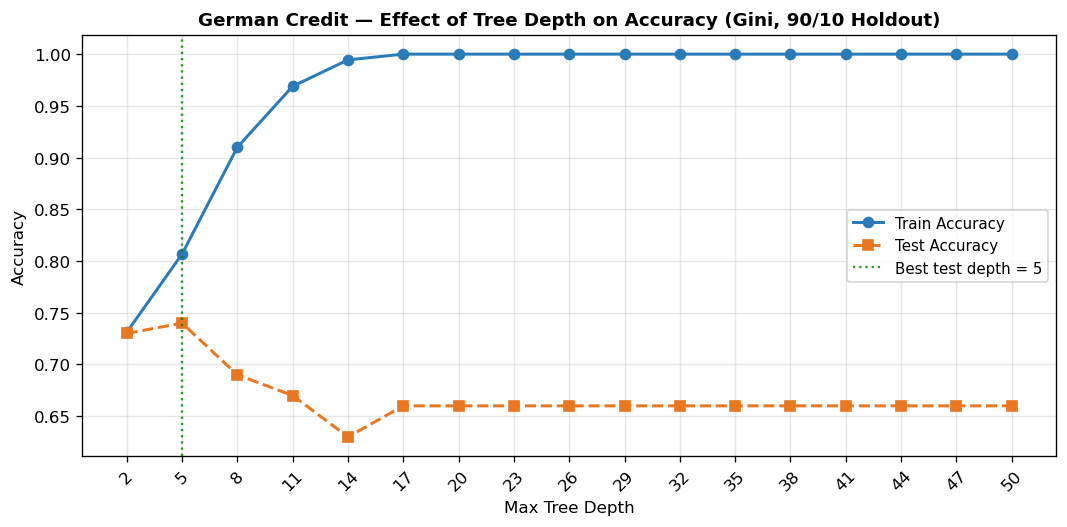

In [14]:
depths = list(range(2, 51, 3))   # [2, 5, 8, 11, ..., 50]

tr_german, te_german = depth_experiment(X_german, y_german, 'gini', depths)

depth_df_german = pd.DataFrame({
    'Max Depth':       depths,
    'Train Accuracy':  [round(a, 4) for a in tr_german],
    'Test Accuracy':   [round(a, 4) for a in te_german],
})

best_idx = int(np.argmax(te_german))
print(f"Best test accuracy: {te_german[best_idx]:.4f} at depth = {depths[best_idx]}")
display(depth_df_german.style
        .highlight_max(subset=['Test Accuracy'], props='font-weight:bold; color:green')
        .highlight_max(subset=['Train Accuracy'], props='color:steelblue')
        .set_properties(**{'text-align': 'center'}))

depth_plot(
    depths, tr_german, te_german,
    'German Credit — Effect of Tree Depth on Accuracy (Gini, 90/10 Holdout)',
    f'{OUT}/german_depth_effect.png')

## 3.2 Waveform — Depth Effect

Best test accuracy: 0.7940 at depth = 8


,Max Depth,Train Accuracy,Test Accuracy
0,2,0.703100,0.718000
1,5,0.799600,0.770000
2,8,0.908400,0.794000
3,11,0.967800,0.772000
4,14,0.991800,0.780000
5,17,0.999300,0.748000
6,20,1.000000,0.744000
7,23,1.000000,0.744000
8,26,1.000000,0.744000
9,29,1.000000,0.744000


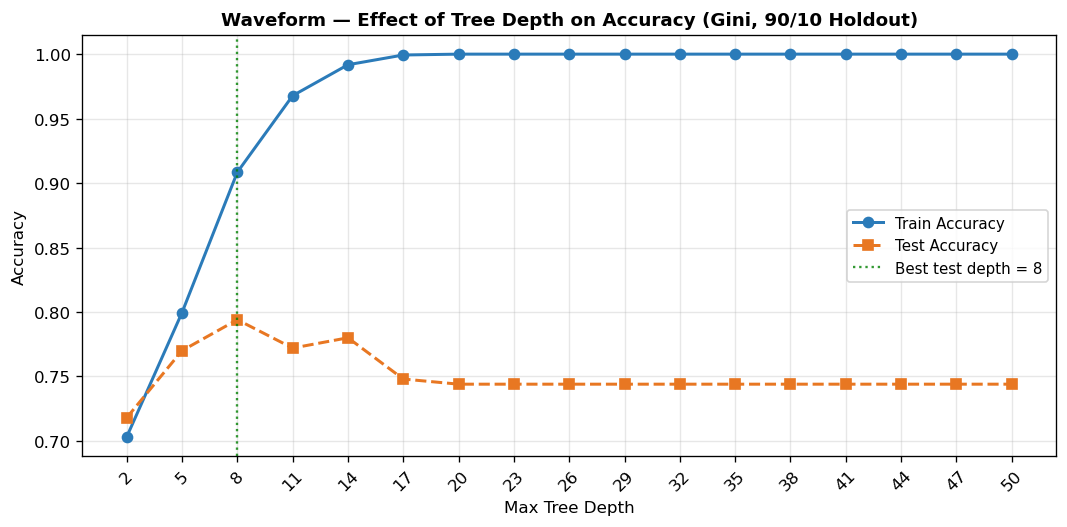

In [15]:
tr_wave, te_wave = depth_experiment(X_wave, y_wave, 'gini', depths)

depth_df_wave = pd.DataFrame({
    'Max Depth':       depths,
    'Train Accuracy':  [round(a, 4) for a in tr_wave],
    'Test Accuracy':   [round(a, 4) for a in te_wave],
})

best_idx_w = int(np.argmax(te_wave))
print(f"Best test accuracy: {te_wave[best_idx_w]:.4f} at depth = {depths[best_idx_w]}")
display(depth_df_wave.style
        .highlight_max(subset=['Test Accuracy'], props='font-weight:bold; color:green')
        .highlight_max(subset=['Train Accuracy'], props='color:steelblue')
        .set_properties(**{'text-align': 'center'}))

depth_plot(
    depths, tr_wave, te_wave,
    'Waveform — Effect of Tree Depth on Accuracy (Gini, 90/10 Holdout)',
    f'{OUT}/wave_depth_effect.png')

## 3.3 Observations

| Observation | German Credit | Waveform |
|-------------|:---:|:---:|
| Train accuracy saturates at 100% by depth | ~17 | ~20 |
| Best test accuracy | 0.740 @ depth=5 | 0.794 @ depth=8 |
| Saturated test accuracy (large depth) | 0.660 | 0.744 |
| Drop from best → saturated | −0.080 | −0.050 |

**Key findings:**

1. **Train accuracy** increases monotonically with depth — the tree eventually memorises every training example (100% train accuracy).
2. **Test accuracy** follows an inverted U: it first rises as the tree gains discriminative power, then *falls* as the tree overfits noise in the training data.
3. The **bias–variance trade-off** is clearly visible: shallow trees underfit (high bias); deep trees overfit (high variance).
4. Optimal depth is dataset-dependent: depth=5 for German Credit, depth=8 for Waveform — reflecting differences in problem complexity and dataset size.
5. **Practical recommendation**: constrain `max_depth` via cross-validated grid search, or use `ccp_alpha` (cost-complexity pruning) in scikit-learn.

---
## Save Numerical Results

In [16]:
def df_to_records(df):
    return df.to_dict(orient='records')

results = {
    'german': {
        'gini':    {'holdout': df_to_records(ho_german_gini), 'cv': df_to_records(cv_german_gini)},
        'entropy': {'holdout': df_to_records(ho_german_ent),  'cv': df_to_records(cv_german_ent)},
        'depths': depths, 'train_accs': tr_german, 'test_accs': te_german,
    },
    'wave': {
        'gini':    {'holdout': df_to_records(ho_wave_gini), 'cv': df_to_records(cv_wave_gini)},
        'entropy': {'holdout': df_to_records(ho_wave_ent),  'cv': df_to_records(cv_wave_ent)},
        'depths': depths, 'train_accs': tr_wave, 'test_accs': te_wave,
    },
}

with open(f'{OUT}/results.json', 'w') as f:
    json.dump(results, f, indent=2)

print("Results saved to:", f'{OUT}/results.json')
print("Figures saved to:", OUT)

Results saved to: /Users/abdullah/Documents/Data_Mining/Labs/Lab 3/output/results.json
Figures saved to: /Users/abdullah/Documents/Data_Mining/Labs/Lab 3/output
